# **LangGraph**

# **AGENT**
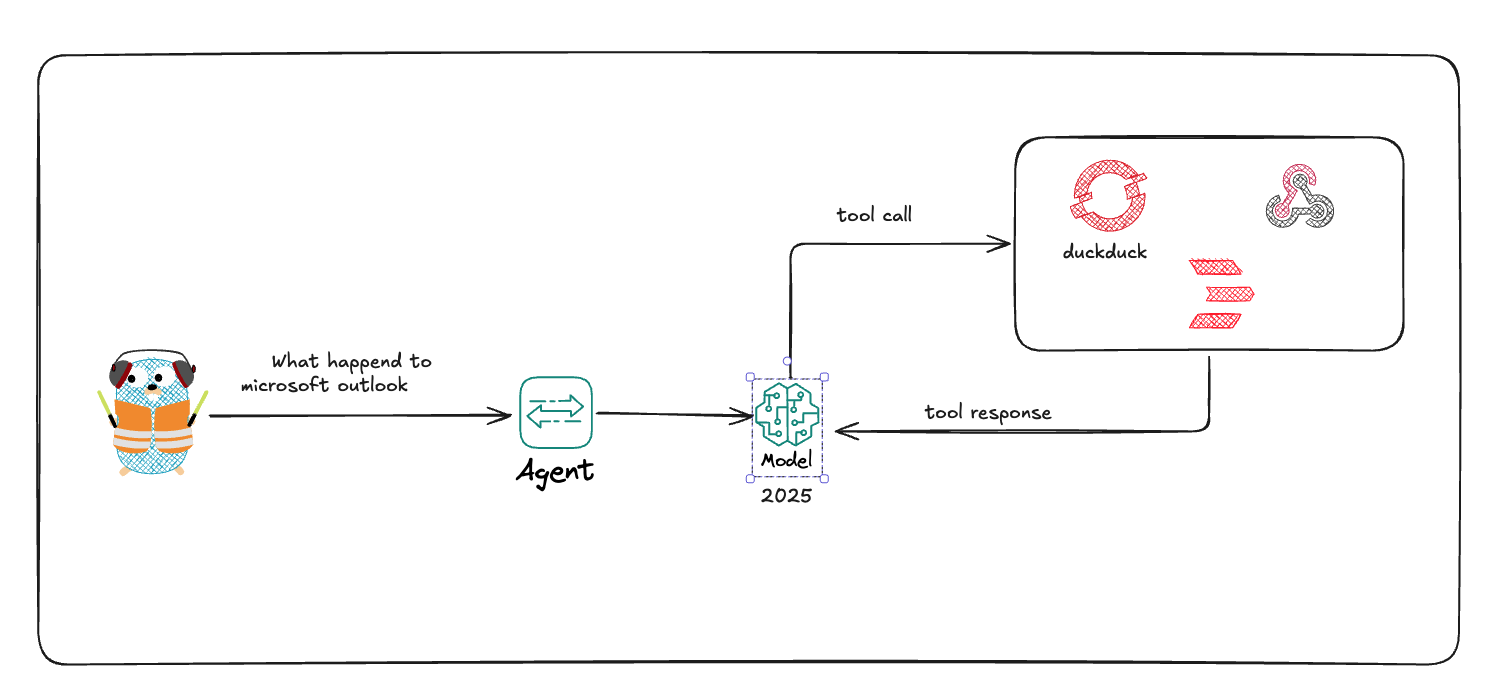

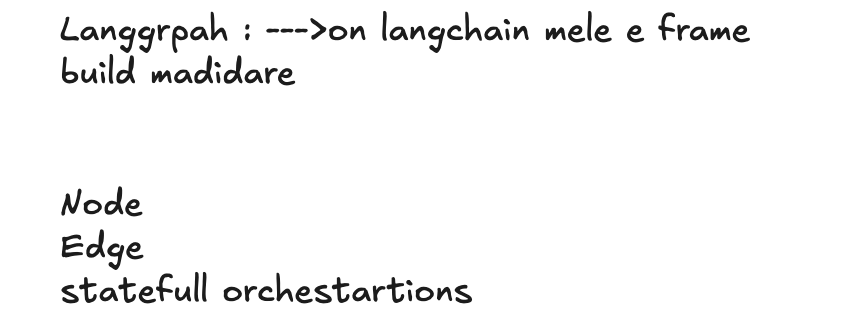

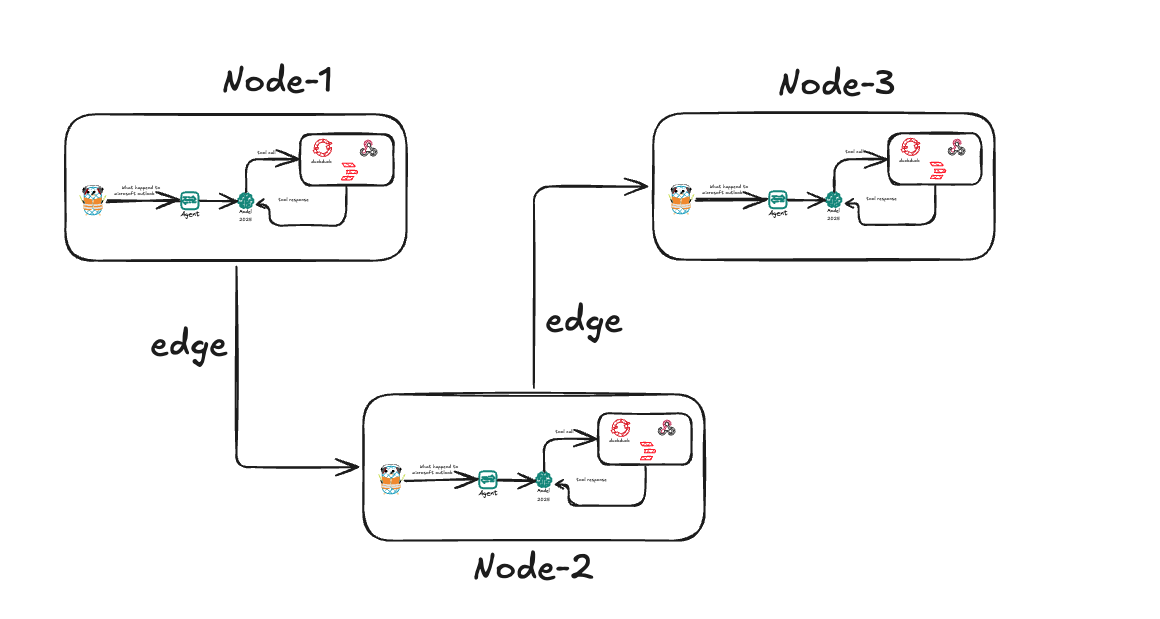

## **LLM initialisation**

In [29]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

from langchain_groq import ChatGroq

llm = ChatGroq(
    model = "openai/gpt-oss-120b"
)

In [30]:
llm.invoke("can you tell me what happend with microsoft outlook..today").content

'**What’s happening with Microsoft\u202fOutlook today (Nov\u202f14\u202f2026)**  \n\n| Time (UTC) | Event | Impact | Current status |\n|------------|-------|--------|----------------|\n| 06:15\u202f–\u202f07:00 | **Authentication‑service glitch** – a mis‑configured load‑balancer in the Azure\u202fActive\u202fDirectory front‑end caused token‑validation failures. | Users of Outlook on the web (OWA), Outlook for iOS/Android, and the desktop client were unable to sign in; some already‑signed‑in sessions were silently logged out. | Issue was mitigated at\u202f07:12\u202fUTC. Sign‑in is now working for >99\u202f% of users; Microsoft reports <0.5\u202f% of customers still experiencing intermittent delays (expected to clear within the next hour). |\n| 09:30\u202f–\u202f09:45 | **Service‑health notification** – Microsoft posted a health‑status update on the Office\u202f365 admin portal confirming the root cause (load‑balancer rule) and the steps taken. | No further impact. | Resolved – “Service

In [31]:
##

### **STEP-1** **Defining Schema**

In [32]:
from typing import TypedDict, List

class graph_schema(TypedDict):
    name: str
    message: str

## **Step-2: Node Creation**

In [33]:
def welcome(schema:graph_schema)-> graph_schema:
    cuurent_name = schema['name']
    cuurent_message = schema["message"]

    response = llm.invoke(f"My name is {cuurent_name} and {cuurent_message}").content

    schema["message"] = f" Nodappa your message is this {cuurent_message} and model agiruva nanu answer madthidane idu nanna answer {response}"

    return schema

## **STEP-3 Creating the First state Graph**

In [34]:
from langgraph.graph import StateGraph,START,END


graph = StateGraph(graph_schema)

## Adding nodes
graph.add_node("ITKWElcome",welcome)

## Adding edges
graph.add_edge(START,"ITKWElcome")
graph.add_edge("ITKWElcome",END)


## **STEP-4 Compilation of the graph**

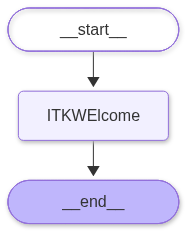

In [35]:
from IPython.display import Image, display

frist_lang_gra = graph.compile()

Image(frist_lang_gra.get_graph().draw_mermaid_png())

In [36]:
print(frist_lang_gra.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	ITKWElcome(ITKWElcome)
	__end__([<p>__end__</p>]):::last
	__start__ --> ITKWElcome;
	ITKWElcome --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## **STEP-5 invoking**

In [37]:
frist_lang_gra.invoke({"name":"ITK","message":"can you explain me about kubernetes"})

{'name': 'ITK',
 'message': ' Nodappa your message is this can you explain me about kubernetes and model agiruva nanu answer madthidane idu nanna answer Hi\u202fITK! 👋  \nSure thing—let’s dive into Kubernetes. I’ll give you a high‑level overview, walk through its core building blocks, and show how it’s used to run containers at scale.\n\n---\n\n## 1. What is Kubernetes?\n\n**Kubernetes (often abbreviated “K8s”)** is an open‑source platform for automating the deployment, scaling, and management of containerized applications.  \nThink of it as an “operating system for the cloud” that turns a bunch of machines (physical or virtual) into a single, resilient compute pool.\n\n| Why it exists | What it does |\n|---------------|--------------|\n| **Containers are great** for packaging code + dependencies, but they’re lightweight and don’t provide built‑in orchestration. | **Kubernetes orchestrates containers**: it decides where they run, how many copies you need, how they talk to each other, a

In [39]:


frist_lang_gra.invoke({"name":"ITK","message":"how are you"})

{'name': 'ITK',
 'message': ' Nodappa your message is this how are you and model agiruva nanu answer madthidane idu nanna answer Hello ITK! I’m doing great, thanks for asking. How about you? Is there anything I can help you with today?'}